**← Previous:** [Policy](09_policy.ipynb)  
**→ Next:** [Drift](11_drift.ipynb)

```text
Reporting
├── Import & Setup
├── Reporting preparation
└── Reporting
```

#### Import & Setup 

In [1]:
# Init work dir

from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
# Standard modules

import pandas as pd

# Framework

from src.decisioning import estimate_capital_reduction, show_approval_vs_reduction
from src.feature_engineering import create_target_def12
from src.modelling import apply_pipe_PD, apply_pipe_LGD, estimate_capital
from src.plots import plot_distribution, plot_heatmap, plot_loss_distribution
from src.preprocessing import input_load
from src.reporting import create_risk_report
from src.utils import preview_pdf

# Dataset specific settings

from src import settings_dataset_unsecured as settings

# Configuration

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)
from sklearn import set_config; set_config(transform_output="pandas")

In [3]:
# load input file

portfolio = input_load(2021, 2021, column_date=settings.COLUMN_DATE, column_year=settings.COLUMN_YEAR)
portfolio, dr_summary = create_target_def12(portfolio, 
                                            settings.COLUMN_DATE,
                                            settings.COLUMN_YEAR, 
                                            settings.COLUMN_TARGET_DATE,
                                            settings.COLUMN_TARGET, 
                                            verbose=False,
                                            )

In [4]:
# load PD, LGD pipelines

import joblib
pipeline_pd  = joblib.load("../models/PIPELINE_PD_ver_012.pkl")
pipeline_lgd = joblib.load("../models/PIPELINE_LGD_Amount.pkl")

# estimate PD, LGD

portfolio = apply_pipe_PD(portfolio, pipeline_pd)
portfolio = apply_pipe_LGD(portfolio, pipeline_lgd)

# run Monte-Carlo

portfolio_cap, loss_summary, el_summary, sim_losses = estimate_capital(portfolio, 
                                                                       method="monte-carlo", 
                                                                       column_lgd="LGD",
                                                                       column_def=settings.COLUMN_TARGET,
                                                                       column_ead=settings.COLUMN_EAD,
                                                                       allocate=True, 
                                                                       verbose=False)

## Reporting Preparation

In [5]:
# Portfolio Overview

overview = {
    "Dataset": ", ".join(map(str, sorted(portfolio[settings.COLUMN_YEAR].unique()))),
    "Nr. of Exposures": f"{len(portfolio):,}",
    "Total Exposure": f"{portfolio[settings.COLUMN_EAD].sum():,.0f}",
    "Mean PD": f"{portfolio['PD'].mean():.2%}",
    "Mean LGD": f"{portfolio['LGD'].mean():.2%}",
}

# plots: Distributions

ead_distribution = plot_distribution(portfolio, "Amount")
pd_distribution  = plot_distribution(portfolio, "PD")
lgd_distribution = plot_distribution(portfolio, "LGD")

In [6]:
# Portfolio Risk

expected_loss    = el_summary["EL (deterministic)"]
expected_loss_mc = el_summary["EL (MC-simulated)"]
var_999          = loss_summary["VaR 99.9%"]
economic_capital = loss_summary["Economic Capital"]

# plots: Capital Allocation

expected_loss_by_pd_lgd = plot_heatmap(portfolio_cap, variable="EL" , column_lgd="LGD", show=False)
econo_capital_by_pd_lgd = plot_heatmap(portfolio_cap, variable="CAP", column_lgd="LGD", show=False)
loss_fig                = plot_loss_distribution(sim_losses, portfolio[settings.COLUMN_EAD].sum(), show_plot=False)

selected variable:  EL
selected variable:  CAP


In [7]:
# Portfolio Strategy

reduction = estimate_capital_reduction(portfolio, 
                                       [1.00, 0.25, 0.20, 0.15, 0.10, 0.08, 0.05], 
                                       column_lgd="LGD",
                                       column_def=settings.COLUMN_TARGET, 
                                       column_ead=settings.COLUMN_EAD)

# plot

approval_vs_reduction = show_approval_vs_reduction(reduction, show_plot=False, invert_y=False)


running Monte-Carlo...  PD threshold:  1.0
running Monte-Carlo...  PD threshold:  0.25
running Monte-Carlo...  PD threshold:  0.2
running Monte-Carlo...  PD threshold:  0.15
running Monte-Carlo...  PD threshold:  0.1
running Monte-Carlo...  PD threshold:  0.08
running Monte-Carlo...  PD threshold:  0.05


## Reporting

In [8]:
# create PDF

create_risk_report(
    overview,
    pd_distribution,
    lgd_distribution,
    ead_distribution,
    expected_loss_by_pd_lgd,
    econo_capital_by_pd_lgd,
    loss_fig,
    approval_vs_reduction,
    "../slides/reports/"
)

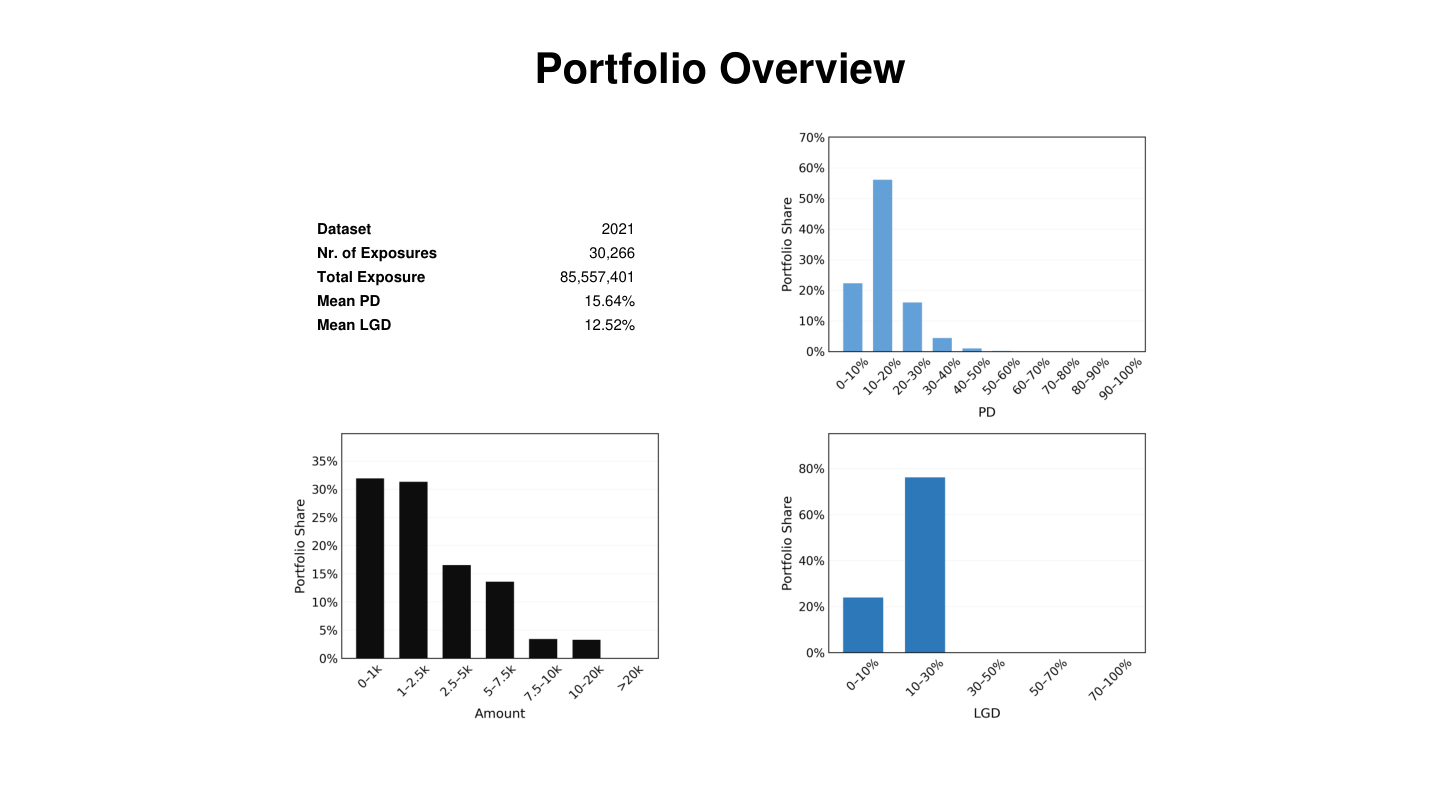

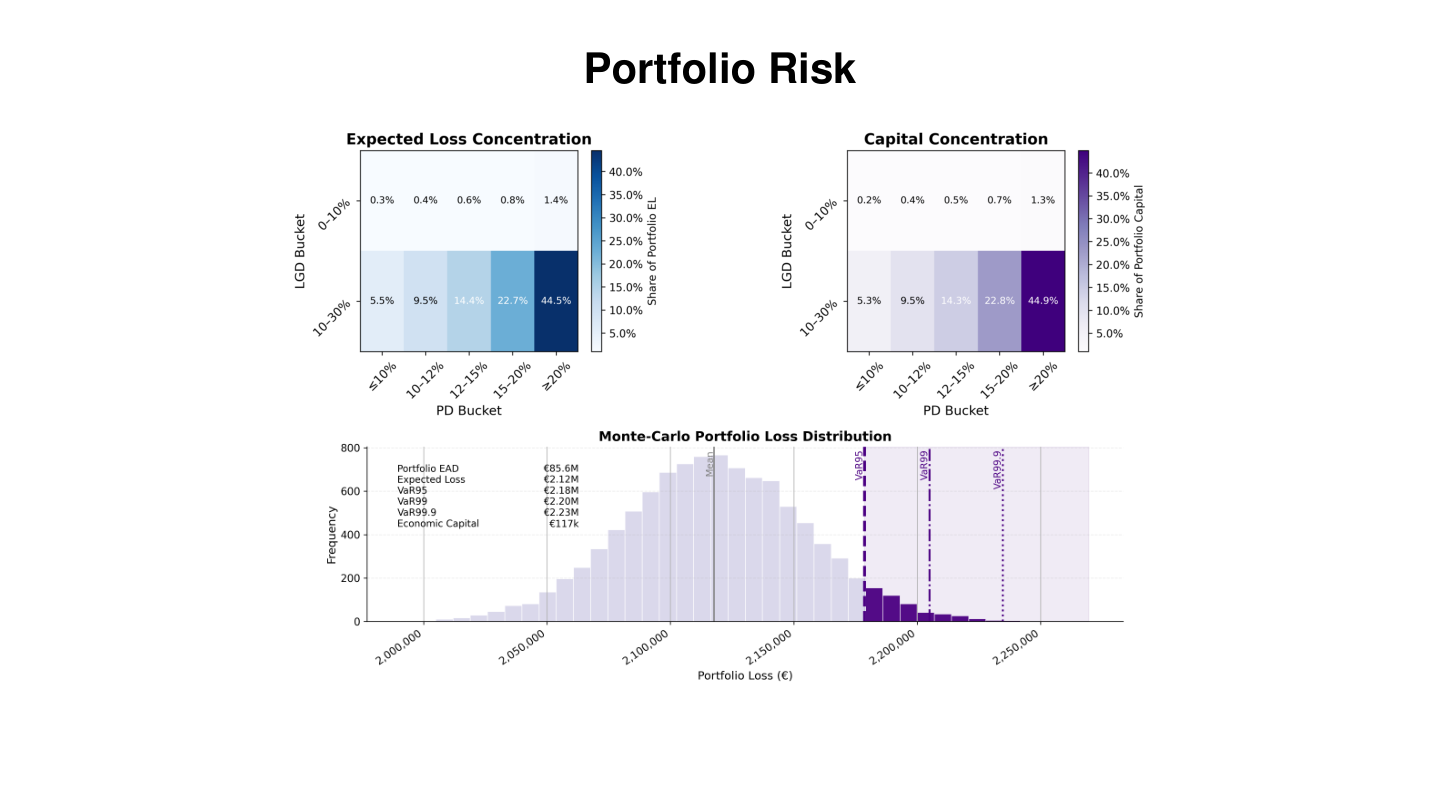

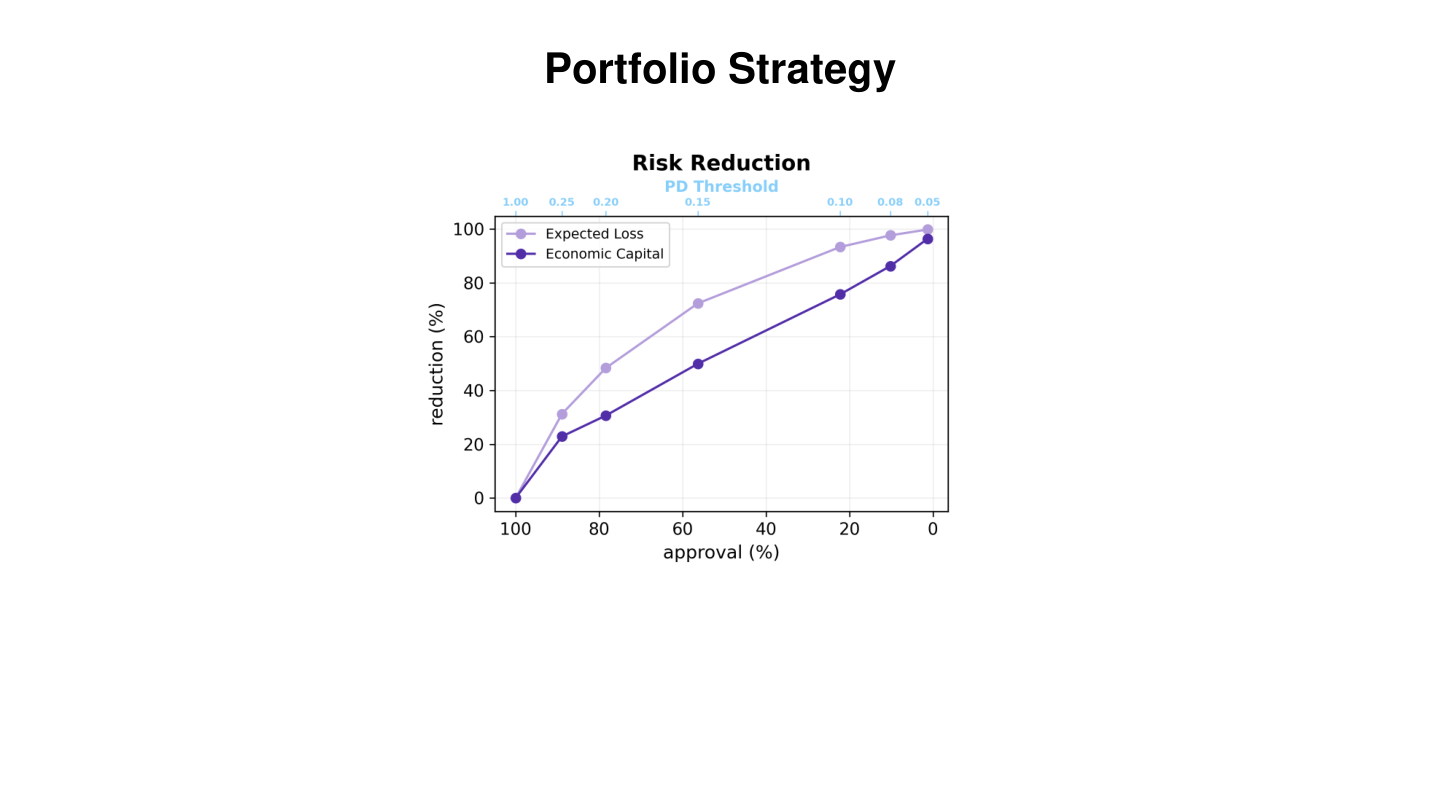

In [9]:
# optional pdf preview in notebook

preview_pdf(pdf_path = "../slides/reports/Test_Report.pdf")